# Análise de um e-commerce de equipamento outdoor (2024–2026)
Este projeto segue as quatro fases de uma análise de dados: **recolha → limpeza → análise exploratória (EDA) → conclusões**.

**Perguntas que guiam a análise**
1. Como evoluem as vendas no tempo? Há sazonalidade?
2. Que categorias, marcas e produtos geram receita e margem?
3. Quem são os clientes e quanto valem?
4. Que canais e métodos de pagamento funcionam melhor?
5. Como correm os envios?
6. Porque é que os clientes devolvem?
7. Os descontos fazem diferença?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import squarify
import warnings
from pywaffle import Waffle
from pypalettes import load_cmap

warnings.filterwarnings('ignore')   # esconde avisos de versões das bibliotecas

# Paleta Acanthurus chirurgus (do azul quase preto ao azul acinzentado)
cmap = load_cmap('Acanthurus_chirurgus')
ESCURO, AZUL, CLARO, CINZA = cmap.colors[0], cmap.colors[1], cmap.colors[3], cmap.colors[4]
ESCALA = sns.blend_palette([CINZA, AZUL, ESCURO], as_cmap=True)        # claro -> escuro

sns.set_theme(style='ticks', palette=[AZUL, CINZA, ESCURO, CLARO], rc={
    'figure.figsize': (10, 4.5),
    'figure.dpi': 100,
    'axes.grid': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
})
pd.options.display.float_format = '{:,.2f}'.format

DOLARES = mticker.StrMethodFormatter('${x:,.0f}')
MILHARES = mticker.StrMethodFormatter('{x:,.0f}')
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

---
## 1. Recolha
Os dados estão em 7 ficheiros CSV, um por tabela:

| ficheiro | conteúdo |
|---|---|
| `customers.csv` | clientes (país, nível de fidelização…) |
| `products.csv` | produtos (categoria, marca, preço, custo…) |
| `orders.csv` | encomendas (data, estado, canal, valores) |
| `order_items.csv` | produtos dentro de cada encomenda |
| `payments.csv` | pagamentos |
| `shipments.csv` | envios |
| `returns.csv` | devoluções |

In [2]:
nomes = ['customers', 'products', 'orders', 'order_items', 'payments', 'shipments', 'returns']
dados = {nome: pd.read_csv(f'{nome}.csv') for nome in nomes}

customers, products, orders = dados['customers'], dados['products'], dados['orders']
order_items, payments = dados['order_items'], dados['payments']
shipments, returns = dados['shipments'], dados['returns']

pd.DataFrame({
    'linhas': {nome: tabela.shape[0] for nome, tabela in dados.items()},
    'colunas': {nome: tabela.shape[1] for nome, tabela in dados.items()},
})

,linhas,colunas
customers,26000,10
products,1500,10
orders,90000,11
order_items,200000,6
payments,90000,6
shipments,83885,7
returns,8000,6


São 26 000 clientes, 1 500 produtos e 90 000 encomendas, com 200 000 produtos vendidos dentro dessas encomendas.

Primeiro olhar para a tabela principal, `orders`:

In [3]:
orders.head()

,order_id,customer_id,order_date,status,channel,subtotal,discount_amount,shipping_fee,tax_amount,total_amount,currency
0,1,1,2026-04-18 22:37:25,delivered,app,14.29,0.00,7.73,1.14,23.16,USD
1,2,1,2025-06-09 08:05:40,delivered,marketplace,630.95,0.00,0.00,50.48,681.43,USD
2,3,1,2024-11-29 08:01:39,delivered,app,345.06,62.79,0.00,22.58,304.85,USD
3,4,1,2024-11-19 20:11:54,delivered,web,431.38,0.00,0.00,34.51,465.89,USD
4,5,2,2025-12-28 04:22:31,delivered,web,613.40,0.00,0.00,49.07,662.47,USD


In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         90000 non-null  int64  
 1   customer_id      90000 non-null  int64  
 2   order_date       90000 non-null  str    
 3   status           90000 non-null  str    
 4   channel          90000 non-null  str    
 5   subtotal         90000 non-null  float64
 6   discount_amount  90000 non-null  float64
 7   shipping_fee     90000 non-null  float64
 8   tax_amount       90000 non-null  float64
 9   total_amount     90000 non-null  float64
 10  currency         90000 non-null  str    
dtypes: float64(5), int64(2), str(4)
memory usage: 7.6 MB


A tabela tem 90 000 encomendas e nenhum valor em falta. A coluna `order_date` aparece como texto (`str`) e não como data, por isso tem de ser corrigida na limpeza.

---
## 2. Limpeza
### 2.1 Valores em falta

In [5]:
em_falta = pd.concat({nome: tabela.isna().sum() for nome, tabela in dados.items()})
em_falta[em_falta > 0]

customers  phone           8645
products   weight_kg         78
shipments  delivered_at     714
dtype: int64

In [6]:
telefones = customers.groupby('country')['phone'].agg(com_telefone='count', clientes='size')
telefones.sort_values('com_telefone')

,com_telefone,clientes
country,,
Germany,0,2302
France,0,1850
Netherlands,0,1063
Italy,0,1059
New Zealand,0,510
Spain,0,1058
Sweden,0,803
Ireland,462,462
Australia,1505,1505


Há valores em falta em três colunas:
- **`phone`**: faltam todos os telefones de 7 países não anglófonos e nenhum dos outros. O telefone simplesmente não foi recolhido nesses países. Como a coluna não é usada na análise, fica como está.
- **`weight_kg`**: 78 produtos sem peso. São preenchidos com a mediana.
- **`delivered_at`**: só pode faltar se a encomenda ainda estiver a caminho. Confirma-se abaixo: há 714 envios `in_transit`, exatamente o número de datas em falta.

In [7]:
products['weight_kg'] = products['weight_kg'].fillna(products['weight_kg'].median())

shipments['status'].value_counts()

status
delivered     83171
in_transit      714
Name: count, dtype: int64

### 2.2 Duplicados

In [8]:
pd.Series({
    'linhas repetidas (todas as tabelas)': sum(tabela.duplicated().sum() for tabela in dados.values()),
    'emails repetidos': customers['email'].duplicated().sum(),
    'order_id repetidos': orders['order_id'].duplicated().sum(),
})

linhas repetidas (todas as tabelas)    0
emails repetidos                       0
order_id repetidos                     0
dtype: int64

Não há linhas repetidas, nem emails ou números de encomenda repetidos.

### 2.3 Tipos de dados
As datas são convertidas de texto para o tipo data, para se poder agrupar por mês e fazer contas com dias.

In [9]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
shipments['shipped_at'] = pd.to_datetime(shipments['shipped_at'])
shipments['delivered_at'] = pd.to_datetime(shipments['delivered_at'])

print(f"Os dados vão de {orders['order_date'].min():%d/%m/%Y} a {orders['order_date'].max():%d/%m/%Y}.")

Os dados vão de 01/01/2024 a 29/09/2026.


Os dados vão de janeiro de 2024 a setembro de 2026. Por isso, 2026 é um ano incompleto.

### 2.4 Valores inválidos
As colunas de texto com poucas opções não podem ter gralhas (por exemplo, "Web" e "web"), e os valores das encomendas têm de ser positivos.

In [10]:
pd.Series({
    'estados da encomenda': sorted(orders['status'].unique()),
    'canais de venda': sorted(orders['channel'].unique()),
    'encomendas com valor ≤ 0': (orders['total_amount'] <= 0).sum(),
})

estados da encomenda        [cancelled, delivered, processing, returned, s...
canais de venda                                [app, marketplace, store, web]
encomendas com valor ≤ 0                                                    0
dtype: object

### 2.5 Consistência entre tabelas
O total de cada encomenda tem de ser igual a subtotal − desconto + portes + imposto. Além disso, cada produto e cada cliente referidos noutras tabelas têm de existir.

In [11]:
total_calculado = orders['subtotal'] - orders['discount_amount'] + orders['shipping_fee'] + orders['tax_amount']

pd.Series({
    'maior diferença no total ($)': (total_calculado - orders['total_amount']).abs().max().round(2),
    'produtos fora do catálogo': (~order_items['product_id'].isin(products['product_id'])).sum(),
    'clientes desconhecidos': (~orders['customer_id'].isin(customers['customer_id'])).sum(),
})

maior diferença no total ($)   0.00
produtos fora do catálogo      0.00
clientes desconhecidos         0.00
dtype: float64

As contas batem certo e não há produtos nem clientes desconhecidos.

### 2.6 Outliers

In [12]:
orders['total_amount'].describe(percentiles=[0.25, 0.5, 0.75, 0.99])

count   90,000.00
mean       570.77
std        582.01
min         13.55
25%        191.23
50%        396.65
75%        749.34
99%      2,816.50
max      9,618.96
Name: total_amount, dtype: float64

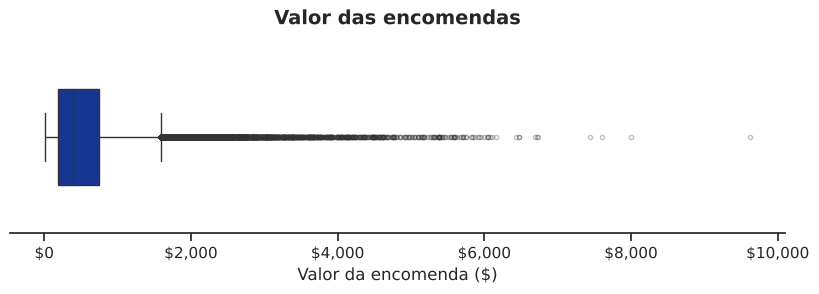

In [13]:
fig, ax = plt.subplots(figsize=(10, 2.5))
sns.boxplot(x=orders['total_amount'], color=AZUL, width=0.5, flierprops={'markersize': 3, 'alpha': 0.3}, ax=ax)
ax.xaxis.set_major_formatter(DOLARES)
ax.set(title='Valor das encomendas', xlabel='Valor da encomenda ($)', yticks=[])
sns.despine(left=True)
plt.show()

In [14]:
orders['customer_id'].value_counts().head()

customer_id
15091    126
24489     87
20141     74
5567      71
4268      64
Name: count, dtype: int64

Há encomendas muito acima da média (os pontos à direita da "caixa") e alguns clientes com dezenas de encomendas. São valores possíveis (encomendas grandes, clientes frequentes) e não erros, por isso **mantêm-se**.

### 2.7 Preparação
Juntam-se numa só tabela (`pedidos`) as encomendas, os clientes, os pagamentos e os envios. Antes disso, as colunas `status` dos pagamentos e dos envios mudam de nome, para não se confundirem com o `status` da encomenda.

In [15]:
payments = payments.rename(columns={'status': 'payment_status'})
shipments = shipments.rename(columns={'status': 'shipment_status'})

pedidos = (
    orders
    .merge(customers, on='customer_id')
    .merge(payments, on='order_id')
    .merge(shipments, on='order_id', how='left')
    .sort_values('order_date')
)

Colunas novas, usadas na análise:

In [16]:
pedidos['mes'] = pedidos['order_date'].dt.to_period('M')
pedidos['ano'] = pedidos['order_date'].dt.year
pedidos['mes_do_ano'] = pedidos['order_date'].dt.month
pedidos['n_itens'] = pedidos['order_id'].map(order_items['order_id'].value_counts())
pedidos['tem_desconto'] = pedidos['discount_amount'] > 0
pedidos['desconto_%'] = pedidos['discount_amount'] / pedidos['subtotal'] * 100
pedidos['dias_expedicao'] = (pedidos['shipped_at'] - pedidos['order_date'].dt.normalize()).dt.days
pedidos['dias_entrega'] = (pedidos['delivered_at'] - pedidos['shipped_at']).dt.days

A tabela `vendas` fica só com as encomendas que não foram canceladas, e indica se o cliente já tinha comprado antes (cliente recorrente). A tabela `itens` tem um produto vendido por linha, com a categoria, o lucro e a indicação de se foi devolvido. A tabela `clientes` resume cada cliente.

In [17]:
vendas = pedidos[pedidos['status'] != 'cancelled'].copy()
vendas['recorrente'] = vendas.duplicated('customer_id')  # o cliente já tinha comprado antes?

itens = (
    order_items
    .merge(products[['product_id', 'product_name', 'category', 'brand', 'unit_cost']], on='product_id')
    .merge(vendas[['order_id', 'dias_entrega']], on='order_id')
)
itens['lucro'] = itens['line_total'] - itens['quantity'] * itens['unit_cost']
itens['devolvido'] = itens['order_item_id'].isin(returns['order_item_id'])

devolucoes = returns.merge(itens, on='order_item_id')
devolucoes['reembolso_%'] = devolucoes['refund_amount'] / devolucoes['line_total'] * 100

clientes = vendas.groupby('customer_id').agg(
    encomendas=('order_id', 'count'),
    gasto=('total_amount', 'sum'),
    valor_medio=('total_amount', 'mean'),
    itens_medios=('n_itens', 'mean'),
    pct_com_desconto=('tem_desconto', 'mean'),
    ultima_compra=('order_date', 'max'),
    nivel=('loyalty_tier', 'first'),
    opt_in=('marketing_opt_in', 'first'),
)
clientes['dias_sem_comprar'] = (vendas['order_date'].max() - clientes['ultima_compra']).dt.days

---
## 3. Análise exploratória (EDA)
### 3.1 Números gerais

In [18]:
pd.Series({
    'Encomendas (todas)': len(pedidos),
    'Encomendas não canceladas': len(vendas),
    'Clientes': vendas['customer_id'].nunique(),
})

Encomendas (todas)           90000
Encomendas não canceladas    84163
Clientes                     25722
dtype: int64

In [19]:
pd.Series({
    'Vendas totais ($)': vendas['total_amount'].sum(),
    'Valor médio por encomenda ($)': vendas['total_amount'].mean(),
    'Valor mediano por encomenda ($)': vendas['total_amount'].median(),
    'Margem bruta (%)': itens['lucro'].sum() / itens['line_total'].sum() * 100,
    'Descontos dados ($)': vendas['discount_amount'].sum(),
    'Reembolsado ($)': returns.loc[returns['status'] == 'refunded', 'refund_amount'].sum(),
})

Vendas totais ($)                 48,049,184.34
Valor médio por encomenda ($)            570.91
Valor mediano por encomenda ($)          396.53
Margem bruta (%)                          47.71
Descontos dados ($)                1,138,605.31
Reembolsado ($)                    1,012,878.51
dtype: float64

In [20]:
vendas[['subtotal', 'discount_amount', 'shipping_fee', 'tax_amount', 'total_amount', 'n_itens']].describe()

,subtotal,discount_amount,shipping_fee,tax_amount,total_amount,n_itens
count,"84,163.00","84,163.00","84,163.00","84,163.00","84,163.00","84,163.00"
mean,541.55,13.53,0.64,42.24,570.91,2.22
std,552.35,43.67,2.14,43.20,582.58,1.12
min,8.15,0.00,0.00,0.56,13.55,1.00
25%,183.35,0.00,0.00,14.17,191.27,1.00
50%,377.71,0.00,0.00,29.37,396.53,2.00
75%,712.97,0.00,0.00,55.45,748.55,3.00
max,"8,906.44","1,252.28",9.99,712.52,"9,618.96",10.00


Foram **48 milhões de dólares em vendas**, com uma margem bruta de 48%. A média por encomenda ($571) é bem maior do que a mediana ($397), porque algumas encomendas grandes puxam a média para cima.

### 3.2 Distribuições

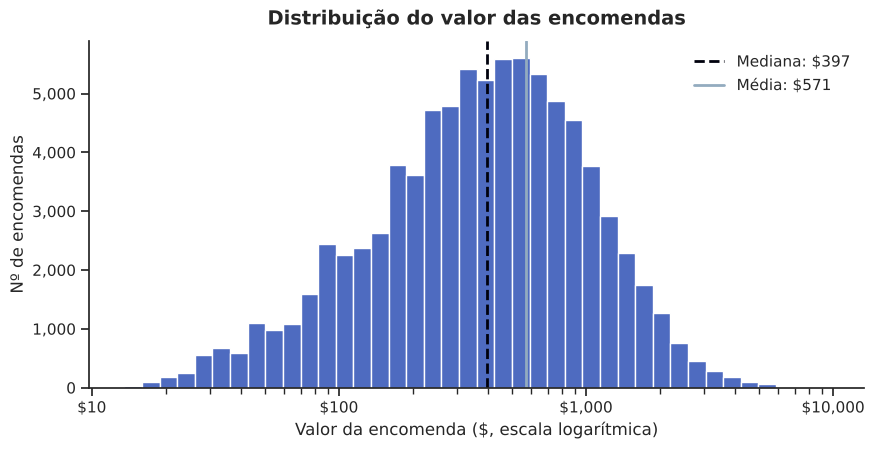

In [21]:
media, mediana = vendas['total_amount'].agg(['mean', 'median'])

fig, ax = plt.subplots()
sns.histplot(vendas['total_amount'], bins=40, log_scale=True, color=AZUL, alpha=0.7, ax=ax)
ax.axvline(mediana, color=ESCURO, ls='--', lw=2, label=f'Mediana: ${mediana:,.0f}')
ax.axvline(media, color=CINZA, ls='-', lw=2, label=f'Média: ${media:,.0f}')
ax.xaxis.set_major_formatter(DOLARES)
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_major_formatter(MILHARES)
ax.set(title='Distribuição do valor das encomendas',
       xlabel='Valor da encomenda ($, escala logarítmica)', ylabel='Nº de encomendas')
ax.legend(frameon=False)
plt.show()

Numa escala logarítmica, o valor das encomendas tem a forma de um sino, o que é típico de valores em dinheiro. A maioria das encomendas tem 1 a 3 produtos, e quase sempre 1 unidade de cada.

### 3.3 Vendas ao longo do tempo

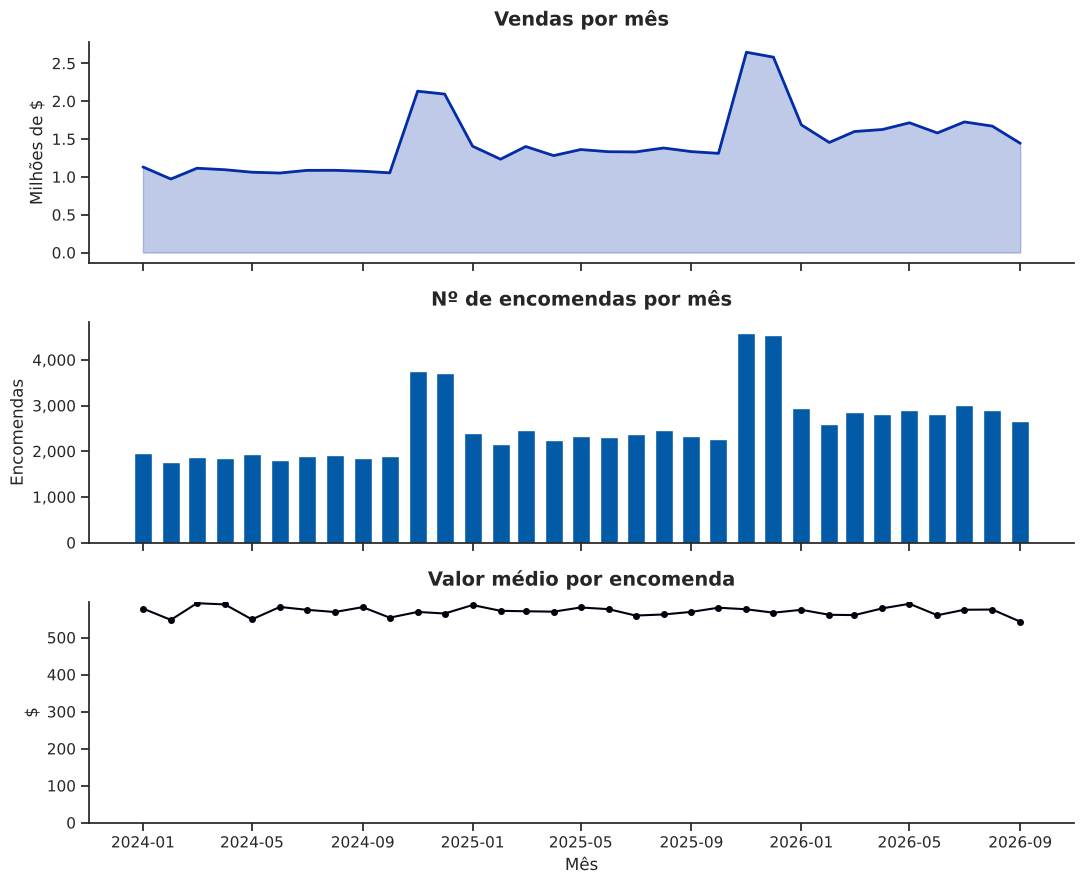

In [22]:
mensal = vendas.groupby('mes').agg(
    vendas=('total_amount', 'sum'),
    encomendas=('order_id', 'count'),
    valor_medio=('total_amount', 'mean'),
)
mensal.index = mensal.index.to_timestamp()

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

axes[0].plot(mensal.index, mensal['vendas'] / 1e6, color=AZUL, lw=2)
axes[0].fill_between(mensal.index, mensal['vendas'] / 1e6, color=AZUL, alpha=0.25)
axes[0].set(title='Vendas por mês', ylabel='Milhões de $')

axes[1].bar(mensal.index, mensal['encomendas'], width=20, color=CLARO)
axes[1].yaxis.set_major_formatter(MILHARES)
axes[1].set(title='Nº de encomendas por mês', ylabel='Encomendas')

axes[2].plot(mensal.index, mensal['valor_medio'], color=ESCURO, marker='o', markersize=4)
axes[2].set(title='Valor médio por encomenda', ylabel='$', xlabel='Mês', ylim=(0, None))

plt.tight_layout()
plt.show()

Como 2026 só tem dados até setembro, os anos comparam-se sempre de janeiro a setembro:

In [23]:
anual = vendas[vendas['mes_do_ano'] <= 9].groupby('ano').agg(
    vendas=('total_amount', 'sum'),
    encomendas=('order_id', 'count'),
    valor_medio=('total_amount', 'mean'),
)
anual['crescimento_vendas_%'] = anual['vendas'].pct_change() * 100
anual

,vendas,encomendas,valor_medio,crescimento_vendas_%
ano,,,,
2024,"9,670,397.28",16850,573.91,NaN
2025,"12,058,717.17",21079,572.07,24.70
2026,"14,501,847.45",25474,569.28,20.26


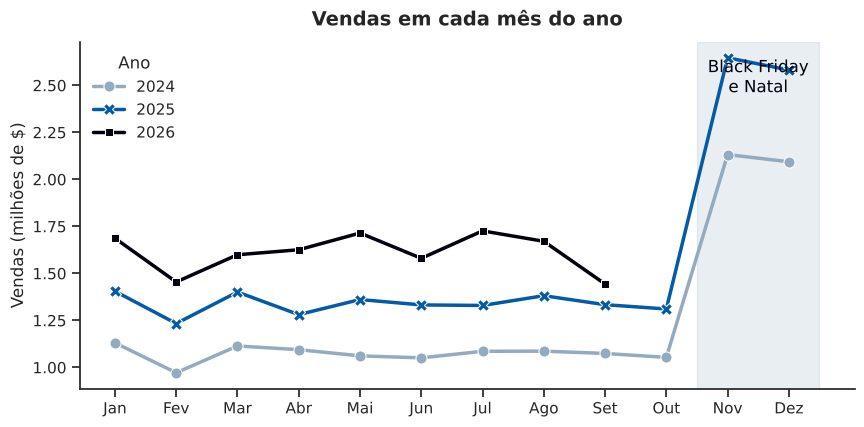

In [24]:
vendas_mes_ano = vendas.pivot_table(index='mes_do_ano', columns='ano', values='total_amount', aggfunc='sum') / 1e6

fig, ax = plt.subplots()
sns.lineplot(data=vendas_mes_ano, palette=[CINZA, CLARO, ESCURO], markers=True, dashes=False, lw=2.5, markersize=8, ax=ax)
ax.axvspan(10.5, 12.5, color=CINZA, alpha=0.2)
ax.text(11.5, vendas_mes_ano.max().max(), 'Black Friday\ne Natal', ha='center', va='top', color=ESCURO)
ax.set_xticks(range(1, 13), MESES)
ax.set(title='Vendas em cada mês do ano', xlabel='', ylabel='Vendas (milhões de $)')
ax.legend(title='Ano', frameon=False)
plt.show()

In [25]:
vendas.groupby(vendas['order_date'].dt.date)['total_amount'].sum().nlargest(10)

order_date
2025-11-04   110,453.70
2025-11-27   108,468.04
2025-11-20   104,154.96
2025-12-19   104,111.82
2025-11-22   103,710.88
2025-12-12   103,624.78
2025-11-03   102,646.12
2025-11-07   101,339.63
2025-12-30    99,134.52
2025-12-20    98,013.10
Name: total_amount, dtype: float64

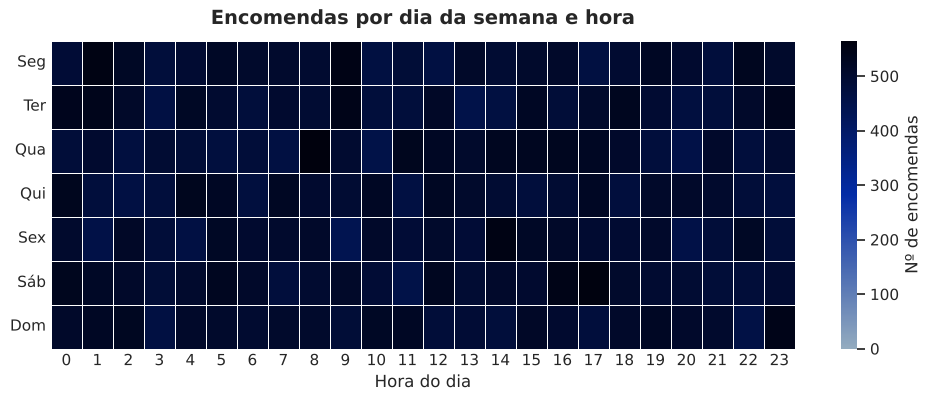

In [26]:
dia_hora = pd.crosstab(vendas['order_date'].dt.dayofweek, vendas['order_date'].dt.hour)
dia_hora.index = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(dia_hora, cmap=ESCALA, vmin=0, linewidths=0.5,
            cbar_kws={'label': 'Nº de encomendas'}, ax=ax)
ax.set(title='Encomendas por dia da semana e hora', xlabel='Hora do dia', ylabel='')
ax.tick_params(axis='y', rotation=0, length=0)
ax.tick_params(axis='x', length=0)
plt.show()

- **As vendas crescem:** +25% em 2025 e +20% em 2026. O crescimento vem de mais encomendas; o valor médio por encomenda mantém-se (~$570).
- **Novembro e dezembro vendem quase o dobro** de um mês normal (Black Friday e Natal). Os 10 melhores dias são todos dessa época.
- **O dia da semana e a hora não fazem diferença:** as encomendas estão espalhadas por igual, até de madrugada. Isto é pouco realista e é um sinal de que os dados podem ser simulados.

### 3.4 Estado das encomendas

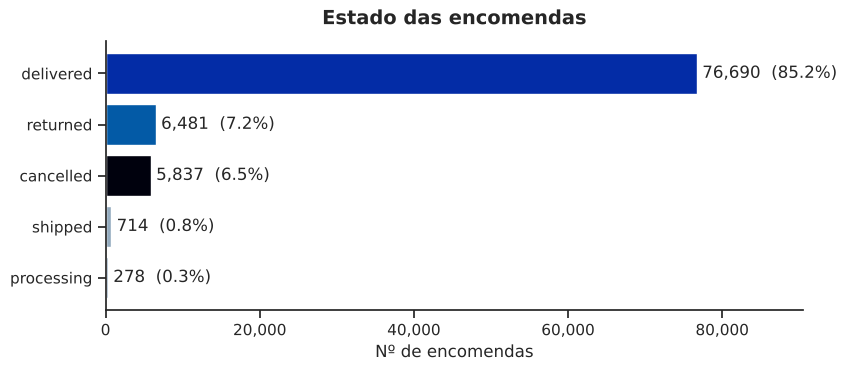

In [27]:
estados = orders['status'].value_counts().sort_values()
cores_estado = {'delivered': AZUL, 'returned': CLARO, 'cancelled': ESCURO, 'shipped': CINZA, 'processing': CINZA}

fig, ax = plt.subplots(figsize=(9, 3.5))
barras = ax.barh(estados.index, estados, color=estados.index.map(cores_estado))
ax.bar_label(barras, labels=[f'{n:,}  ({n / estados.sum():.1%})' for n in estados], padding=4)
ax.xaxis.set_major_formatter(MILHARES)
ax.set(title='Estado das encomendas', xlabel='Nº de encomendas', ylabel='')
ax.margins(x=0.18)
plt.show()

In [28]:
pd.crosstab(pedidos['status'], pedidos['payment_status'])

payment_status,captured,failed,refunded
status,,,
cancelled,0,1718,4119
delivered,76690,0,0
processing,278,0,0
returned,0,0,6481
shipped,714,0,0


In [29]:
cancelados = pedidos[pedidos['status'] == 'cancelled']
cancelados['payment_status'].value_counts(normalize=True) * 100

payment_status
refunded   70.57
failed     29.43
Name: proportion, dtype: float64

85% das encomendas foram entregues, 7% devolvidas e 6,5% canceladas. Dos 5 837 cancelamentos, 1 718 (29%) devem-se a pagamentos que falharam.

### 3.5 Canais de venda

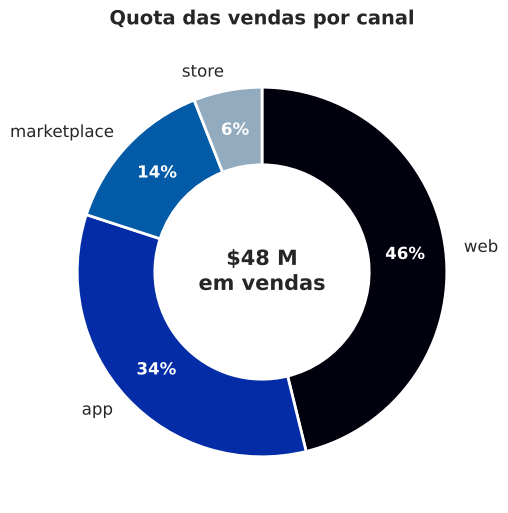

In [30]:
vendas_canal = vendas.groupby('channel')['total_amount'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 6))
_, _, percentagens = ax.pie(vendas_canal, labels=vendas_canal.index, autopct='%.0f%%', startangle=90,
                           counterclock=False, colors=[ESCURO, AZUL, CLARO, CINZA], pctdistance=0.78,
                           textprops={'fontsize': 12}, wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2})
plt.setp(percentagens, color='white', fontweight='bold')
ax.text(0, 0, f'${vendas_canal.sum() / 1e6:.0f} M\nem vendas', ha='center', va='center', fontsize=15, fontweight='bold')
ax.set_title('Quota das vendas por canal')
plt.show()

In [31]:
# quota de encomendas de cada canal, por ano
pd.crosstab(vendas['ano'], vendas['channel'], normalize='index') * 100

channel,app,marketplace,store,web
ano,,,,
2024,34.14,14.01,5.94,45.91
2025,34.26,14.19,5.66,45.88
2026,33.75,14.20,6.19,45.86


In [32]:
por_canal = pd.crosstab(pedidos['channel'], pedidos['status'], normalize='index')[['cancelled', 'returned']] * 100
por_canal['valor_medio'] = vendas.groupby('channel')['total_amount'].mean()
por_canal

status,cancelled,returned,valor_medio
channel,,,
app,6.43,7.46,567.39
marketplace,6.65,7.25,565.20
store,6.44,6.36,578.13
web,6.48,7.11,574.34


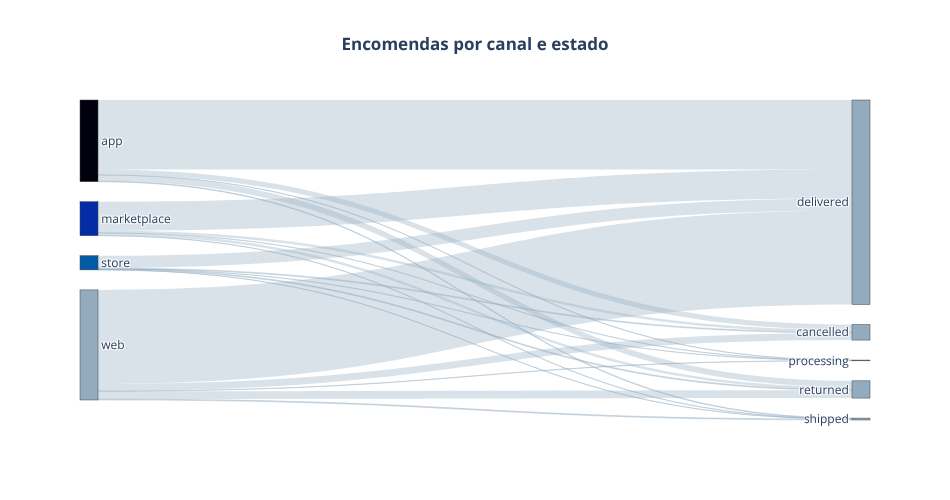

In [33]:
# Sankey: para onde vão as encomendas de cada canal
fluxo = pedidos.groupby(['channel', 'status']).size().reset_index(name='encomendas')
nos = list(fluxo['channel'].unique()) + list(fluxo['status'].unique())

fig = go.Figure(go.Sankey(
    node=dict(label=nos, color=[ESCURO, AZUL, CLARO, CINZA] + [CINZA] * 5, pad=20, thickness=18),
    link=dict(source=fluxo['channel'].map(nos.index), target=fluxo['status'].map(nos.index),
              value=fluxo['encomendas'], color='rgba(147, 171, 191, 0.35)'),
))
fig.update_layout(title='<b>Encomendas por canal e estado</b>', title_x=0.5, width=950, height=500)
fig.show(renderer='png')

O site (`web`, 46%) e a `app` (34%) dominam, e as quotas mantêm-se ao longo do tempo. O valor médio e as taxas de cancelamento e devolução são praticamente iguais em todos os canais.

### 3.6 Categorias, produtos e marcas

In [34]:
categorias = itens.groupby('category').agg(vendas=('line_total', 'sum'), lucro=('lucro', 'sum'),
                                          devolvidos_pct=('devolvido', 'mean'))
categorias['margem_%'] = categorias['lucro'] / categorias['vendas'] * 100
categorias['%_das_vendas'] = categorias['vendas'] / categorias['vendas'].sum() * 100
categorias['devolvidos_pct'] *= 100
categorias.sort_values('vendas', ascending=False)

,vendas,lucro,devolvidos_pct,margem_%,%_das_vendas
category,,,,,
Tents,"8,572,395.26","4,011,842.22",4.06,46.80,18.81
Backpacks,"7,658,349.06","3,780,501.91",4.31,49.36,16.80
Navigation,"7,027,757.13","3,463,414.17",4.37,49.28,15.42
Sleeping Bags,"5,555,680.60","2,693,049.26",4.16,48.47,12.19
Footwear,"4,559,251.19","1,925,107.78",4.27,42.22,10.00
Climbing,"3,711,958.25","1,788,936.12",4.44,48.19,8.14
Apparel,"3,232,127.67","1,588,273.05",4.21,49.14,7.09
Accessories,"2,138,815.91","1,015,772.58",4.20,47.49,4.69
Cooking,"2,113,057.85","988,958.27",4.21,46.80,4.64


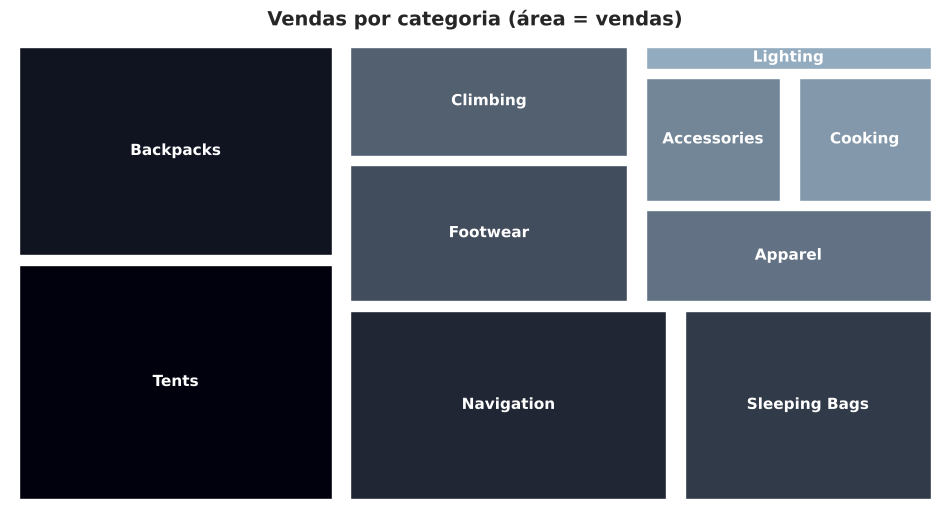

In [35]:
por_vendas = categorias.sort_values('vendas', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
squarify.plot(sizes=por_vendas['vendas'], label=por_vendas.index, pad=True, ax=ax,
              color=sns.blend_palette([ESCURO, CINZA], len(por_vendas)),
              text_kwargs={'color': 'white', 'fontsize': 11, 'fontweight': 'bold'})
ax.set_title('Vendas por categoria (área = vendas)')
ax.axis('off')
plt.show()

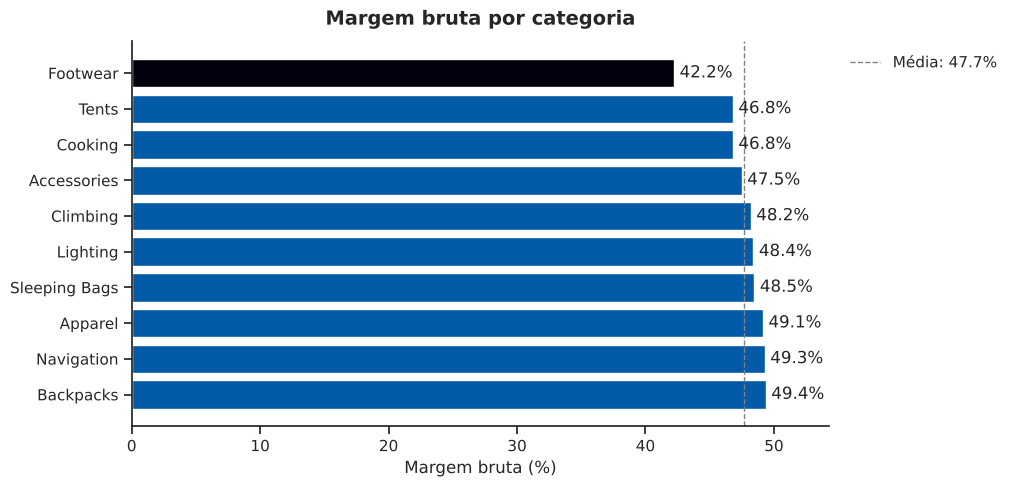

In [36]:
margem = categorias['margem_%'].sort_values(ascending=False)
margem_total = itens['lucro'].sum() / itens['line_total'].sum() * 100
cores = [ESCURO if categoria == margem.idxmin() else CLARO for categoria in margem.index]

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(margem.index, margem, color=cores)
ax.bar_label(barras, fmt='%.1f%%', padding=4)
ax.axvline(margem_total, color='grey', ls='--', lw=1, label=f'Média: {margem_total:.1f}%')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.set(title='Margem bruta por categoria', xlabel='Margem bruta (%)', ylabel='')
ax.margins(x=0.1)
plt.show()

In [37]:
top10 = itens.groupby('product_name')['line_total'].sum().nlargest(10).to_frame('vendas')
top10['%_das_vendas'] = top10['vendas'] / itens['line_total'].sum() * 100
top10

,vendas,%_das_vendas
product_name,,
Tundra Hydration Pack (Moss),"2,735,927.28",6.00
Summit Trail Runner (Sand),"1,575,448.16",3.46
Tundra 45L Backpack (Ember),"941,773.95",2.07
Glacier 45L Backpack (Graphite),"806,054.80",1.77
Nomad 3-Season Sleeping Bag (Cobalt),"636,583.86",1.40
Solstice Handheld GPS (Cobalt),"586,233.44",1.29
Nomad Handheld GPS (Sand),"561,964.16",1.23
Alpine Climbing Harness (Sand),"515,892.02",1.13
Solstice 4-Season Tent (Sand),"501,407.56",1.10


**Curva de Pareto:** mostra quanto das vendas vem dos produtos que mais vendem. Ordeno os produtos do que mais vende para o que menos vende e vou somando as vendas (`cumsum`). No eixo horizontal fica a % de produtos e no vertical a % acumulada das vendas, por isso basta ler a curva nos 20% para ver quanto valem os produtos do topo.

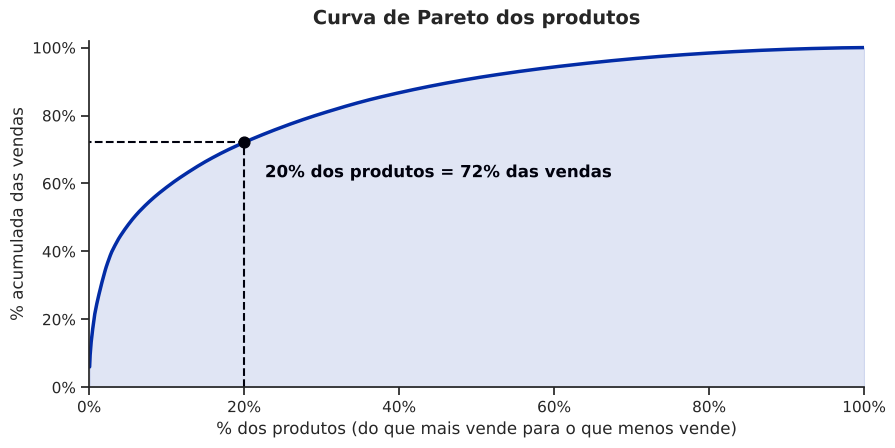

In [38]:
por_produto = itens.groupby('product_id')['line_total'].sum().sort_values(ascending=False)
pareto = por_produto.cumsum() / por_produto.sum() * 100
pareto.index = np.arange(1, len(pareto) + 1) / len(pareto) * 100   # % dos produtos
top20 = pareto[pareto.index <= 20].iloc[-1]

fig, ax = plt.subplots()
ax.plot(pareto.index, pareto, color=AZUL, lw=2.5)
ax.fill_between(pareto.index, pareto, color=AZUL, alpha=0.12)
ax.plot([20, 20, 0], [0, top20, top20], color=ESCURO, ls='--', lw=1.5)
ax.scatter(20, top20, color=ESCURO, s=60, zorder=3)
ax.annotate(f'20% dos produtos = {top20:.0f}% das vendas', (20, top20), xytext=(15, -25),
            textcoords='offset points', color=ESCURO, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set(title='Curva de Pareto dos produtos', xlabel='% dos produtos (do que mais vende para o que menos vende)',
       ylabel='% acumulada das vendas', xlim=(0, 100), ylim=(0, 102))
plt.show()

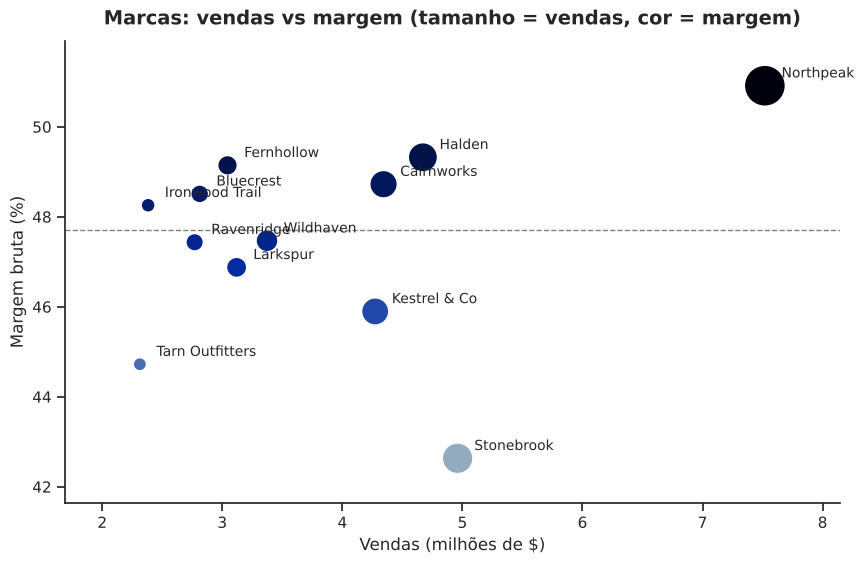

In [39]:
marcas = itens.groupby('brand').agg(vendas=('line_total', 'sum'), lucro=('lucro', 'sum'))
marcas['vendas_milhoes'] = marcas['vendas'] / 1e6
marcas['margem_%'] = marcas['lucro'] / marcas['vendas'] * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=marcas, x='vendas_milhoes', y='margem_%', size='vendas_milhoes', sizes=(100, 900),
                hue='margem_%', palette=ESCALA, edgecolor='white', linewidth=1.5, legend=False, ax=ax)
for marca, linha in marcas.iterrows():
    ax.annotate(marca, (linha['vendas_milhoes'], linha['margem_%']), xytext=(12, 6),
                textcoords='offset points', fontsize=10)
ax.axhline(margem_total, color='grey', ls='--', lw=1)
ax.set(title='Marcas: vendas vs margem (tamanho = vendas, cor = margem)', xlabel='Vendas (milhões de $)', ylabel='Margem bruta (%)')
ax.margins(0.12)
plt.show()

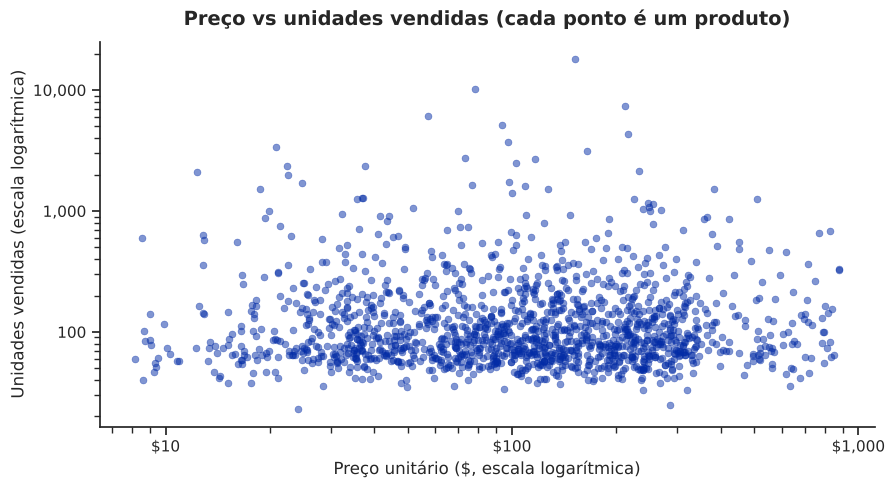

,unit_price,margem_%,weight_kg,unidades_vendidas
unit_price,1.00,0.00,-0.00,-0.02
margem_%,0.00,1.00,0.00,0.02
weight_kg,-0.00,0.00,1.00,0.02
unidades_vendidas,-0.02,0.02,0.02,1.00


In [40]:
produtos = products.join(itens.groupby('product_id')['quantity'].sum().rename('unidades_vendidas'), on='product_id')
produtos['margem_%'] = (produtos['unit_price'] - produtos['unit_cost']) / produtos['unit_price'] * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=produtos, x='unit_price', y='unidades_vendidas', color=AZUL, alpha=0.5, s=25,
                edgecolor=None, ax=ax)
ax.set(xscale='log', yscale='log', title='Preço vs unidades vendidas (cada ponto é um produto)',
       xlabel='Preço unitário ($, escala logarítmica)', ylabel='Unidades vendidas (escala logarítmica)')
ax.xaxis.set_major_formatter(DOLARES)
ax.yaxis.set_major_formatter(MILHARES)
plt.show()

produtos[['unit_price', 'margem_%', 'weight_kg', 'unidades_vendidas']].corr()

- **Tents, Backpacks e Navigation valem metade das vendas** (19% + 17% + 15% = 51%). São também as categorias mais caras.
- **Footwear tem a margem mais baixa** (42%, contra 47–49% nas outras). Nas marcas, a Northpeak lidera em vendas e em margem, e a Stonebrook é a 2.ª em vendas mas tem a pior margem (43%).
- **As vendas dependem de poucos produtos:** 20% dos produtos valem 72% das vendas. Só o *Tundra Hydration Pack (Moss)* vale 6% de tudo.
- **O preço não se relaciona com as unidades vendidas** nem com a margem (correlações perto de 0).

### 3.7 Clientes

In [41]:
por_pais = vendas.groupby('country').agg(vendas=('total_amount', 'sum'), clientes=('customer_id', 'nunique'))
por_pais['gasto_por_cliente'] = por_pais['vendas'] / por_pais['clientes']
por_pais['quota_%'] = por_pais['vendas'] / por_pais['vendas'].sum() * 100
por_pais.sort_values('vendas', ascending=False)

,vendas,clientes,gasto_por_cliente,quota_%
country,,,,
United States,"18,453,228.40",9907,"1,862.65",38.40
United Kingdom,"5,701,901.94",3068,"1,858.51",11.87
Canada,"4,355,947.29",2235,"1,948.97",9.07
Germany,"4,220,138.96",2274,"1,855.82",8.78
France,"3,342,736.14",1839,"1,817.69",6.96
Australia,"2,722,020.07",1489,"1,828.09",5.67
Netherlands,"2,046,235.39",1051,"1,946.94",4.26
Spain,"2,020,347.04",1049,"1,925.97",4.20
Italy,"1,885,489.05",1048,"1,799.13",3.92


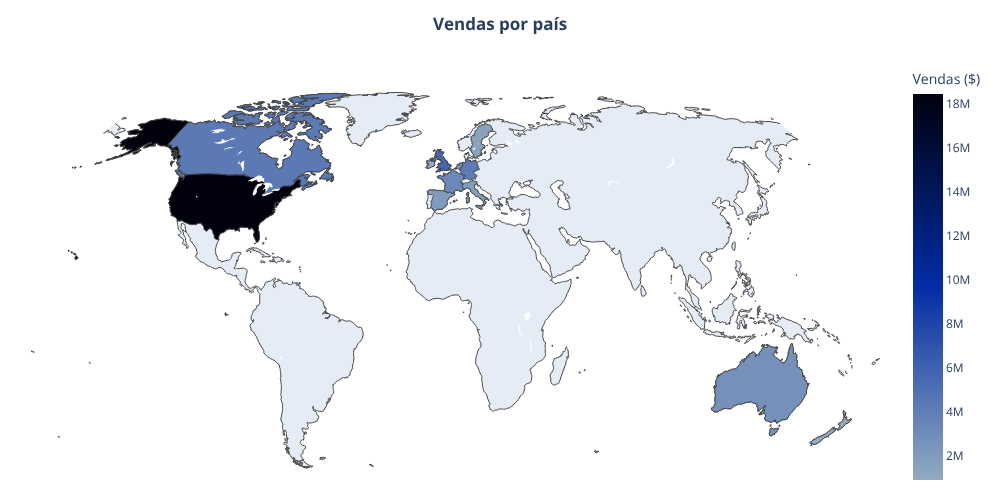

In [42]:
fig = px.choropleth(por_pais.reset_index(), locations='country', locationmode='country names', color='vendas',
                    color_continuous_scale=[CINZA, AZUL, ESCURO], projection='natural earth',
                    labels={'vendas': 'Vendas ($)'}, title='<b>Vendas por país</b>')
fig.update_geos(projection_rotation_lon=0, lataxis_range=[-58, 85], showframe=False)
fig.update_layout(title_x=0.5, width=1000, height=500, margin=dict(l=10, r=10, t=60, b=10))
fig.show(renderer='png')

In [43]:
ordem_niveis = ['none', 'silver', 'gold', 'platinum']
clientes.groupby('nivel')[['encomendas', 'gasto']].mean().reindex(ordem_niveis)

,encomendas,gasto
nivel,,
none,3.27,"1,862.20"
silver,3.29,"1,889.50"
gold,3.25,"1,846.64"
platinum,3.38,"1,951.72"


In [44]:
clientes.groupby('opt_in')[['encomendas', 'gasto']].mean()

,encomendas,gasto
opt_in,,
0,3.29,"1,878.75"
1,3.25,"1,852.12"


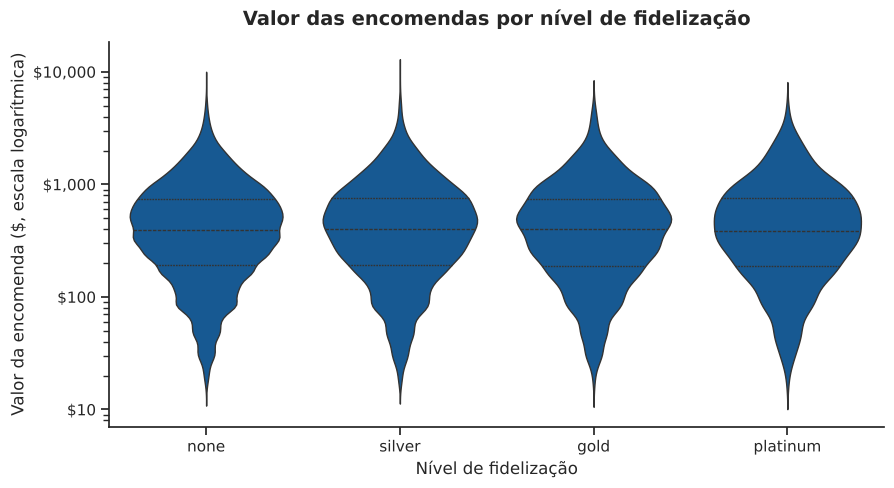

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=vendas, x='loyalty_tier', y='total_amount', order=ordem_niveis, log_scale=True,
               inner='quartile', color=CLARO, linewidth=1, ax=ax)
ax.yaxis.set_major_formatter(DOLARES)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set(title='Valor das encomendas por nível de fidelização', xlabel='Nível de fidelização',
       ylabel='Valor da encomenda ($, escala logarítmica)')
plt.show()

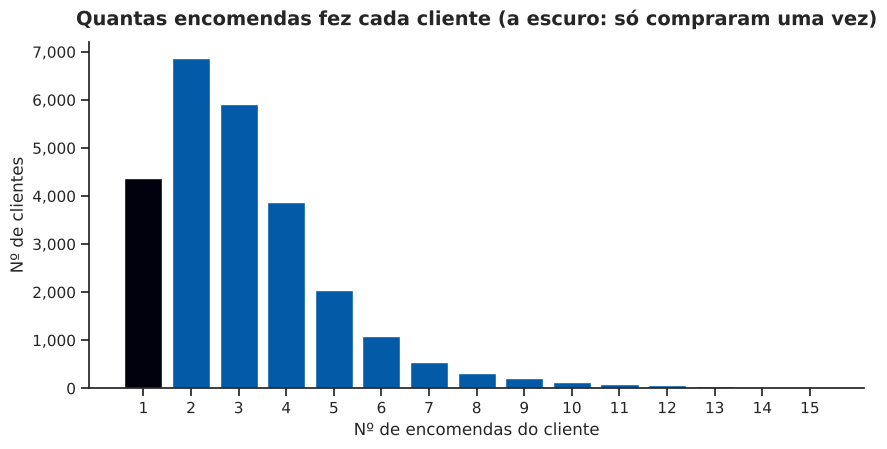

In [46]:
encomendas_por_cliente = clientes['encomendas'].value_counts().sort_index().head(15)
cores = [ESCURO if n == 1 else CLARO for n in encomendas_por_cliente.index]

fig, ax = plt.subplots()
ax.bar(encomendas_por_cliente.index, encomendas_por_cliente, color=cores)
ax.set_xticks(encomendas_por_cliente.index)
ax.yaxis.set_major_formatter(MILHARES)
ax.set(title='Quantas encomendas fez cada cliente (a escuro: só compraram uma vez)',
       xlabel='Nº de encomendas do cliente', ylabel='Nº de clientes')
plt.show()

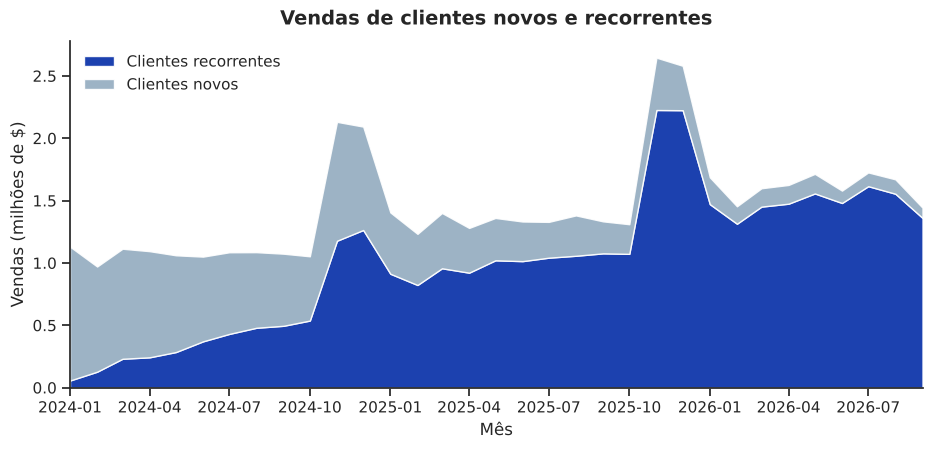

In [47]:
novos_recorrentes = vendas.groupby(['mes', 'recorrente'])['total_amount'].sum().unstack() / 1e6
novos_recorrentes.index = novos_recorrentes.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(novos_recorrentes.index, novos_recorrentes[True], novos_recorrentes[False],
             labels=['Clientes recorrentes', 'Clientes novos'], colors=[AZUL, CINZA], alpha=0.9)
ax.set(title='Vendas de clientes novos e recorrentes', xlabel='Mês', ylabel='Vendas (milhões de $)',
       xlim=(novos_recorrentes.index.min(), novos_recorrentes.index.max()))
ax.legend(loc='upper left', frameon=False)
plt.show()

In [48]:
pct_voltaram = (clientes['encomendas'] > 1).mean() * 100
pct_vendas_recorrentes = vendas.loc[vendas['recorrente'], 'total_amount'].sum() / vendas['total_amount'].sum() * 100

print(f'{pct_voltaram:.0f}% dos clientes voltaram a comprar.')
print(f'{pct_vendas_recorrentes:.0f}% das vendas vêm de clientes recorrentes.')
print(f"Último registo de um cliente: {pd.to_datetime(customers['signup_date']).max():%d/%m/%Y}")

83% dos clientes voltaram a comprar.
69% das vendas vêm de clientes recorrentes.
Último registo de um cliente: 30/12/2023


- **Os EUA são o maior mercado** (38% das vendas), mas cada cliente gasta quase o mesmo em todos os países ($1 800–2 000). A diferença está só no número de clientes.
- **Os clientes são fiéis:** 83% voltam a comprar e 69% das vendas vêm de clientes recorrentes.
- **O nível de fidelização e o opt-in de marketing não mudam o comportamento:** os clientes gastam e encomendam praticamente o mesmo.
- **Quase não entram clientes novos:** todos os clientes registaram-se antes de 2024, e as vendas a clientes novos encolhem ao longo do tempo.

### 3.8 Pagamentos

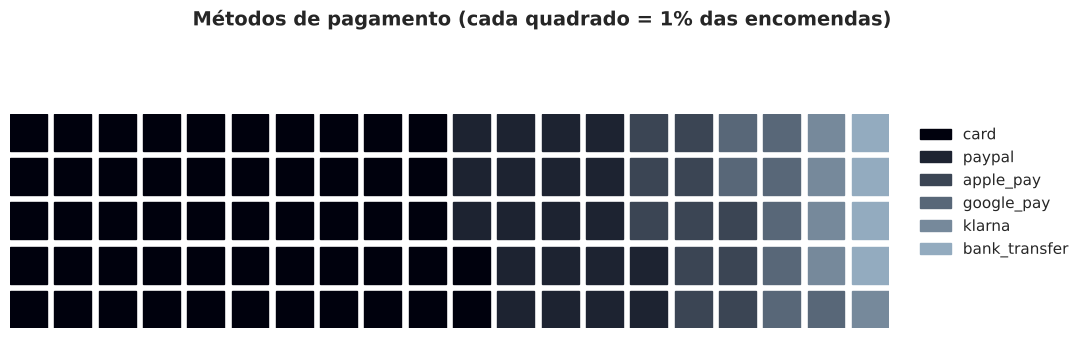

In [49]:
metodos = (pedidos['method'].value_counts(normalize=True) * 100).round().astype(int)

fig = plt.figure(
    FigureClass=Waffle,
    rows=5,
    columns=20,
    values=metodos.to_dict(),
    colors=sns.blend_palette([ESCURO, CINZA], len(metodos)),
    legend={'loc': 'upper left', 'bbox_to_anchor': (1.02, 1), 'frameon': False},
    figsize=(11, 4),
)
fig.suptitle('Métodos de pagamento (cada quadrado = 1% das encomendas)', fontsize=14, fontweight='bold')
plt.show()

In [50]:
pd.crosstab(pedidos['method'], pedidos['payment_status'], normalize='index') * 100

payment_status,captured,failed,refunded
method,,,
apple_pay,85.97,2.10,11.93
bank_transfer,86.96,1.90,11.14
card,86.33,1.88,11.78
google_pay,86.50,1.93,11.57
klarna,85.75,1.93,12.33
paypal,86.39,1.86,11.75


In [51]:
pd.crosstab(pedidos['channel'], pedidos['method'], normalize='index') * 100

method,apple_pay,bank_transfer,card,google_pay,klarna,paypal
channel,,,,,,
app,10.99,3.84,51.89,7.91,4.95,20.41
marketplace,10.84,3.73,51.99,8.10,5.25,20.10
store,11.40,4.16,52.05,7.73,5.08,19.57
web,10.96,4.14,51.82,8.18,4.99,19.92


O cartão é usado em mais de metade das encomendas, seguido do PayPal (20%). Todos os métodos falham em cerca de 2% dos casos. A mistura de métodos é igual em todos os canais, até na loja física (onde 4% pagam por transferência bancária). Também isto é pouco realista.

### 3.9 Envios

In [52]:
vendas[['dias_expedicao', 'dias_entrega']].describe()

,dias_expedicao,dias_entrega
count,"83,885.00","83,171.00"
mean,2.00,5.51
std,0.82,2.29
min,1.00,2.00
25%,1.00,4.00
50%,2.00,6.00
75%,3.00,7.00
max,3.00,9.00


In [53]:
# dias médios de transporte: o mais rápido e o mais lento de cada grupo
dias_medios = pd.concat({
    'transportadora': vendas.groupby('carrier')['dias_entrega'].mean(),
    'país': vendas.groupby('country')['dias_entrega'].mean(),
})
dias_medios.groupby(level=0).agg(['min', 'max'])

,min,max
país,5.48,5.58
transportadora,5.42,5.52


In [54]:
limite_portes = vendas.loc[vendas['shipping_fee'] == 0, 'subtotal'].min()
pct_pagam_portes = (vendas['shipping_fee'] > 0).mean() * 100

print(f'Portes grátis a partir de ${limite_portes:.0f}. Só {pct_pagam_portes:.1f}% das encomendas pagam portes.')

Portes grátis a partir de $75. Só 8.6% das encomendas pagam portes.


- A expedição demora 1 a 3 dias e o transporte 2 a 9 dias (5,5 em média). **Todas as transportadoras e todos os países têm prazos iguais.**
- **Os portes são grátis a partir de $75.** Só 8,6% das encomendas pagam portes.

### 3.10 Devoluções

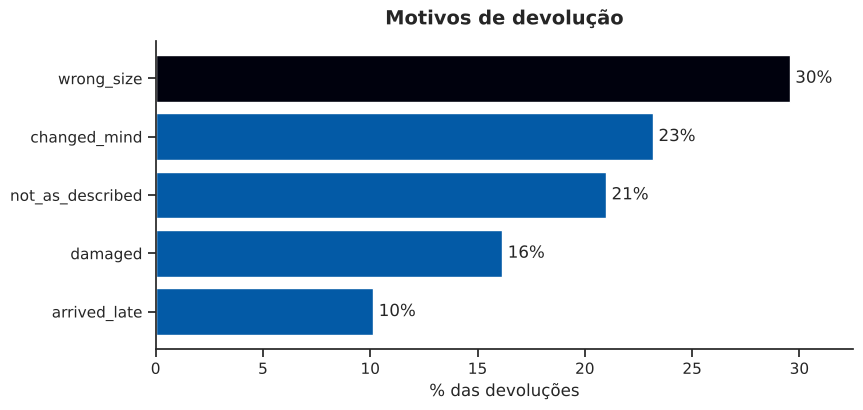

In [55]:
motivos = devolucoes['reason'].value_counts(normalize=True).sort_values() * 100
cores = [ESCURO if motivo == motivos.idxmax() else CLARO for motivo in motivos.index]

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(motivos.index, motivos, color=cores)
ax.bar_label(barras, fmt='%.0f%%', padding=4)
ax.set(title='Motivos de devolução', xlabel='% das devoluções', ylabel='')
ax.margins(x=0.1)
plt.show()

In [56]:
pd.Series({
    '% de produtos vendidos devolvidos': itens['devolvido'].mean() * 100,
    'reembolso médio (% do valor do produto)': devolucoes['reembolso_%'].mean(),
})

% de produtos vendidos devolvidos          4.28
reembolso médio (% do valor do produto)   74.89
dtype: float64

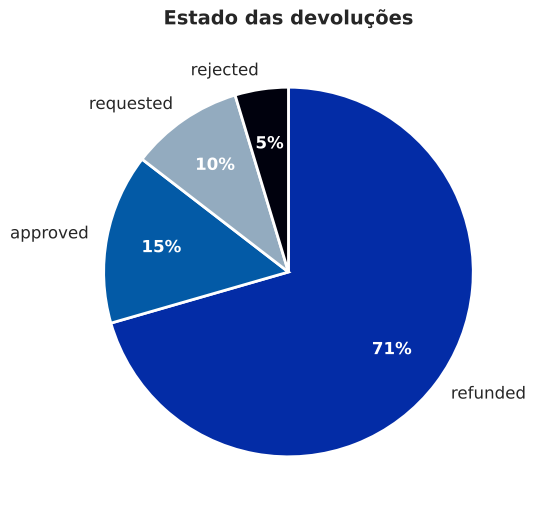

In [57]:
estado_devolucoes = devolucoes['status'].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
_, _, percentagens = ax.pie(estado_devolucoes, labels=estado_devolucoes.index, autopct='%.0f%%', startangle=90,
                           counterclock=False, colors=[AZUL, CLARO, CINZA, ESCURO], pctdistance=0.7,
                           textprops={'fontsize': 12}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.setp(percentagens, color='white', fontweight='bold')
ax.set_title('Estado das devoluções')
plt.show()

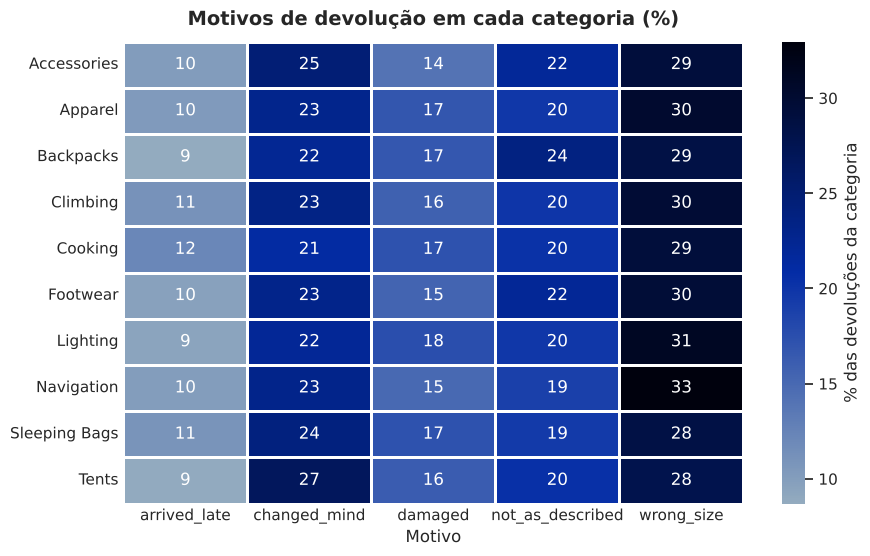

In [58]:
motivo_por_categoria = pd.crosstab(devolucoes['category'], devolucoes['reason'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(motivo_por_categoria, annot=True, fmt='.0f', cmap=ESCALA,
            linewidths=1, cbar_kws={'label': '% das devoluções da categoria'}, ax=ax)
ax.set(title='Motivos de devolução em cada categoria (%)', xlabel='Motivo', ylabel='')
ax.tick_params(length=0)
plt.show()

In [59]:
escalao_preco = pd.qcut(itens['unit_price'], 5, precision=0)
itens.groupby(escalao_preco, observed=True)['devolvido'].mean() * 100

unit_price
(7.0, 42.0]      4.25
(42.0, 84.0]     4.28
(84.0, 141.0]    4.26
(141.0, 216.0]   4.39
(216.0, 881.0]   4.20
Name: devolvido, dtype: float64

In [60]:
devolucoes.groupby('reason')['dias_entrega'].mean()

reason
arrived_late       5.71
changed_mind       5.60
damaged            5.56
not_as_described   5.66
wrong_size         5.47
Name: dias_entrega, dtype: float64

- 4,3% dos produtos vendidos são devolvidos. Em média, o reembolso é de 75% do valor do produto. **25% das devoluções ainda estão por fechar** (pedidas ou aprovadas).
- O motivo n.º 1 é **`wrong_size`** (30%), mas aparece até em GPS e tendas, que não têm tamanho. Os motivos escolhidos pelos clientes parecem pouco fiáveis.
- A taxa de devolução não muda com a categoria nem com o preço. Quem devolve por `arrived_late` não teve um transporte mais longo do que os outros (5,7 vs 5,5 dias).

### 3.11 Descontos

In [61]:
com_desconto = vendas[vendas['tem_desconto']]

pd.Series({
    '% de encomendas com desconto': vendas['tem_desconto'].mean() * 100,
    'desconto mínimo (%)': com_desconto['desconto_%'].min(),
    'desconto máximo (%)': com_desconto['desconto_%'].max(),
})

% de encomendas com desconto   20.18
desconto mínimo (%)             5.00
desconto máximo (%)            20.00
dtype: float64

In [62]:
vendas.groupby('tem_desconto')[['total_amount', 'n_itens']].mean()

,total_amount,n_itens
tem_desconto,,
False,585.90,2.22
True,511.57,2.22


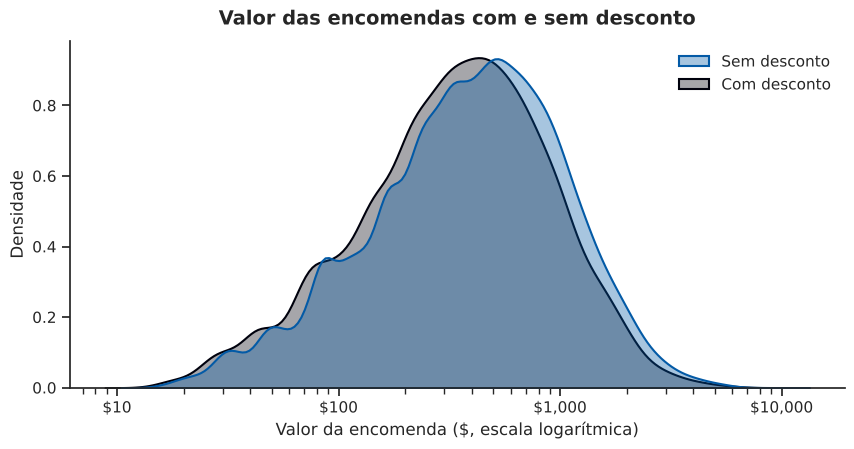

In [63]:
fig, ax = plt.subplots()
desconto = vendas['tem_desconto'].map({True: 'Com desconto', False: 'Sem desconto'})
sns.kdeplot(x=vendas['total_amount'], hue=desconto, log_scale=True, common_norm=False, fill=True, alpha=0.35,
            palette={'Com desconto': ESCURO, 'Sem desconto': CLARO}, linewidth=1.5, ax=ax)
ax.xaxis.set_major_formatter(DOLARES)
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.get_legend().set_title('')
ax.get_legend().set_frame_on(False)
ax.set(title='Valor das encomendas com e sem desconto', xlabel='Valor da encomenda ($, escala logarítmica)',
       ylabel='Densidade')
plt.show()

In [64]:
(vendas.groupby('loyalty_tier')['tem_desconto'].mean() * 100).reindex(ordem_niveis)

loyalty_tier
none       20.15
silver     20.25
gold       20.50
platinum   19.40
Name: tem_desconto, dtype: float64

Uma em cada cinco encomendas tem desconto, de 5% a 20%, num total de 1,1 milhões de dólares. Os descontos são dados por igual a todos os níveis de fidelização. As encomendas com desconto não levam mais produtos e têm um valor médio mais baixo ($512 vs $586).

### 3.12 Correlações
As variáveis de cada encomenda (subtotal, desconto, portes, prazos…) quase não se relacionam entre si, com correlações perto de 0. Por isso faço o correlograma ao nível do **cliente**, com variáveis que descrevem o comportamento de compra: nº de encomendas, gasto total, valor médio por encomenda, nº médio de produtos por encomenda, % de encomendas com desconto e dias desde a última compra.

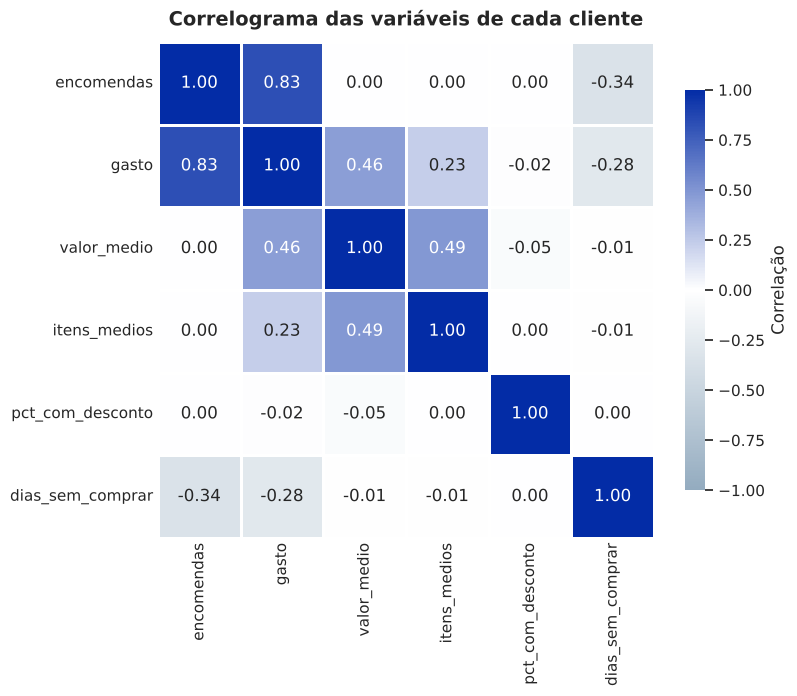

In [65]:
colunas = ['encomendas', 'gasto', 'valor_medio', 'itens_medios', 'pct_com_desconto', 'dias_sem_comprar']
correlacoes = clientes[colunas].corr().round(2) + 0.0   # + 0.0 evita aparecer "-0.00"

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlacoes, annot=True, fmt='.2f', cmap=sns.blend_palette([CINZA, 'white', AZUL], as_cmap=True), vmin=-1, vmax=1,
            linewidths=1, square=True, cbar_kws={'label': 'Correlação', 'shrink': 0.8}, ax=ax)
ax.set_title('Correlograma das variáveis de cada cliente')
ax.tick_params(length=0)
plt.show()

- **O gasto de um cliente depende sobretudo de quantas vezes compra** (0,83 com o nº de encomendas) e menos do valor de cada encomenda (0,46).
- O valor médio por encomenda sobe com o nº de produtos por encomenda (0,49).
- Quem compra mais vezes também comprou há menos tempo (−0,34 entre encomendas e dias sem comprar), o que faz sentido: são os clientes mais ativos.
- **A % de encomendas com desconto não se relaciona com nada**, o que confirma que os descontos não mudam o comportamento dos clientes.

---
## 4. Conclusões

**Sobre os dados**
- Os dados estavam limpos. Havia valores em falta pontuais e datas guardadas como texto, e ambos foram corrigidos. Não há duplicados, valores inválidos nem contas erradas.
- Vários padrões são pouco realistas (horas e prazos uniformes, métodos de pagamento iguais em todos os canais), o que sugere que os dados são simulados.

**Sobre o negócio**
1. **Vendeu 48 milhões de dólares em quase 3 anos e cresce 20–25% por ano**, sobretudo porque há mais encomendas.
2. **Novembro e dezembro são decisivos:** vendem quase o dobro de um mês normal.
3. **As vendas estão concentradas:** Tents, Backpacks e Navigation valem metade, e 20% dos produtos valem 72%.
4. **A margem é boa (48%)**, com dois pontos fracos: a categoria Footwear e a marca Stonebrook.
5. **Os clientes são fiéis** (83% voltam a comprar), mas quase não entram clientes novos (não há registos desde 2024).
6. **O programa de fidelização e os descontos não mudam o comportamento** dos clientes.
7. **As perdas são moderadas:** 6,5% de cancelamentos (29% por pagamentos falhados) e 4,3% de produtos devolvidos.
8. **Os canais, os pagamentos e os envios comportam-se todos de forma igual:** o site e a app fazem 80% das vendas, o cartão é usado em mais de metade das encomendas, e todas as transportadoras demoram cerca de 5,5 dias.

**Recomendações**
- Preparar stock e logística para novembro e dezembro.
- Garantir stock dos produtos que mais vendem.
- Rever os preços e os custos de Footwear e da Stonebrook.
- Testar descontos dirigidos em vez de descontos para todos.
- Rever o programa de fidelização e investir em captar clientes novos.
- Melhorar o formulário de devoluções, para os motivos serem fiáveis.